# 01 FÍSICA DO SENSOR ICESAT-2/ATLAS, GEOMETRIA ORBITAL, CONTROLE DE QUALIDADE ATL06 E CORREÇÕES GEOFÍSICAS

Este caderno apresenta a engenharia física do sensor **ATLAS** (*Advanced Topographic Laser Altimeter System*) a bordo do satélite **ICESat-2**, o funcionamento interno do algoritmo de recuperação de elevação sobre gelo terrestre (**ATL06 Release 007**; Smith et al., 2019), as armadilhas de decodificação de tempo e valores de preenchimento dos grânulos HDF5, a auditoria empírica dos flags de qualidade sobre $118{,}6\text{ milhões}$ de segmentos no Mar de Amundsen e o encadeamento das correções geofísicas (maré CATS2008 v2023, DAC, diferenciação topográfica REMA v2 e filtro along-track por MAD móvel).

---

## 1. Física e Geometria do Sensor ATLAS / ICESat-2

### 1.1 Lidar Contador de Fótons e Geometria dos 6 Feixes
Diferentemente do seu antecessor ICESat/GLAS (que operava com forma de onda analógica completa a $40\text{ Hz}$ num único feixe infravermelho de $1064\text{ nm}$), o sensor **ATLAS** do ICESat-2 opera no espectro verde ($\lambda = 532\text{ nm}$) em regime de **contagem de fótons individuais** a uma taxa de repetição de **$10\text{ kHz}$** (Markus et al., 2017; Neumann et al., 2019). Com velocidade orbital no solo de $\sim 7\text{ km/s}$, os disparos consecutivos ficam espaçados a cada **$\sim 0{,}7\text{ m}$** ao longo da trilha, iluminando pegadas circulares de $\sim 11\text{--}17\text{ m}$ de diâmetro.

Um elemento óptico difrativo divide cada pulso laser em **6 feixes** organizados em **3 pares** (`gt1l/gt1r`, `gt2l/gt2r`, `gt3l/gt3r`):
- **Separação entre pares (cross-track):** $\sim 3{,}3\text{ km}$;
- **Separação intra-par (entre feixe esquerdo e direito):** **$90\text{ m}$** perpendiculares à trilha e $\sim 2{,}5\text{ km}$ ao longo da trilha;
- **Permite medir diretamente a declividade transversal ($\partial h / \partial y_{\text{atc}}$)** dentro de cada par na mesma passagem, separando inclinação transversal de variação temporal ($\partial h / \partial t$);
- **Razão de energia forte/fraco ($4:1$):** cada par possui um feixe forte e um feixe fraco. **Atenção crítica (`SCI-14`):** os rótulos `gt1l..gt3r` designam a posição esquerda/direita em relação ao vetor velocidade no solo, e **não** a energia do feixe! A correspondência entre `gt[1-3][l/r]` e feixe forte/fraco inverte sempre que o satélite executa uma manobra de guinada de $180^\circ$ (*spacecraft orientation*: `forward` vs. `backward`) para otimizar a iluminação solar dos painéis fotovoltaicos.

### 1.2 Do Fóton Geolocalizado (ATL03) ao Segmento de Gelo Terrestre (ATL06)
O algoritmo **ATL06** (Smith et al., 2019, *RSE*) agrupa os fótons do ATL03 em **segmentos de $40\text{ m}$ de comprimento com passo de $20\text{ m}$** ao longo da trilha (*50% de superposição*, razão pela qual resíduos de segmentos adjacentes possuem correlação mecânica de lag 1) e ajusta um modelo linear local:
$$h(x_{\text{atc}}) = h_{\text{LI}} + \frac{\partial h}{\partial x_{\text{atc}}}(x_{\text{atc}} - x_0)$$
aplicando duas correções instrumentais essenciais:
1. **Correção de *First-Photon Bias* (`fpb_med_corr`):** Os tubos fotomultiplicadores (PMTs) possuem um tempo morto (*dead time*) de $\sim 3{,}2\text{ ns}$ após detectar um fóton. Em superfícies de alta refletância como a neve antártica, os primeiros fótons do pulso refletido saturam os canais, deslocando o centroide aparente da superfície para cima em alguns centímetros;
2. **Correção da Forma do Pulso Transmitido (`tx_med_corr`):** Compensa a assimetria temporal da cauda do pulso laser emitido.

### 1.3 Armadilhas Críticas do Formato HDF5 do ATL06 (Auditadas e Tratadas em `thwaites.io.extract`)
1. **Conversão de tempo juliano (`delta_time`):** O ATL06 registra o tempo em segundos GPS decorridos desde a época `2018-01-01T00:00:00Z`. Converter `delta_time` usando o ano juliano padrão da missão ($365{,}25\text{ dias} = 31.557.600\text{ s}$) via `2018.0 + delta_time / (365.25 * 86400)` acumula uma deriva de $\sim 18\text{ horas}$ até 2025 em relação ao calendário civil Gregoriano. Nos limites de uma estação (ex.: 31 de agosto às 23h vs. 1º de setembro), usar ano decimal aproximado desloca grânulos entre JJA e SON. O pipeline extrai a data civil exata do timestamp orbital para classificação sazonal (`DJF` do ano $Y$ = dezembro de $Y-1$ + janeiro e fevereiro de $Y$);
2. **Valores de preenchimento (*Fill Values*) que são floats finitos:** No HDF5 do ATL06, valores ausentes em variáveis de ponto flutuante (`dac`, `tide_ocean`, `geoid`, `h_li`) são codificados como `3.4028235e38` (`FLT_MAX` em 32 bits), e flags inteiros como `127` (`INT8_MAX`). **Para o NumPy, `np.isfinite(3.4e38)` retorna `True`!** Se não forem convertidos explicitamente em `NaN` para $|v| > 10^{30}$ na leitura, um único valor de preenchimento corrompe médias e regressões;
3. **Maré e DAC fornecidas, mas NÃO aplicadas em `h_li`:** Conforme documentado no ATBD do ATL03/ATL06 (e verificado empiricamente neste projeto por regressão de trilhas repetidas sobre plataformas flutuantes, que retornou inclinação $+0{,}98 \pm 0{,}05$ contra a maré), `h_li` já vem corrigido apenas de maré terrestre sólida (`tide_earth`), maré de carga (`tide_load`) e maré polar (`tide_pole`), mas **não** de maré oceânica (`tide_ocean`) nem de DAC (`dac`).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from thwaites import load_config

cfg = load_config("jja")
cats_got = json.loads((DATA_DIR / "jja_cats_vs_got.json").read_text(encoding="utf-8"))
qc_rep = json.loads((DATA_DIR / "jja_qc_report.json").read_text(encoding="utf-8"))
ibeam = pd.read_csv(DATA_DIR / "jja_interbeam_bias.csv")

# Geometria dos 6 feixes do ATLAS/ICESat-2 e resumo da comparação CATS2008 vs GOT4.8
pd.DataFrame([
    {"Propriedade Instrumental / Geofísica": "Comprimento de onda / Taxa de pulso / Espaçamento along-track", "Especificação / Valor Medido no Projeto": "532 nm (verde) | 10 kHz | ~0,7 m por disparo (pegada ~14 m)"},
    {"Propriedade Instrumental / Geofísica": "Comprimento do segmento ATL06 / Passo entre centros", "Especificação / Valor Medido no Projeto": "40 m de janela com centros a cada 20 m (50% de superposição)"},
    {"Propriedade Instrumental / Geofísica": "Arranjo de feixes (3 pares × 2 feixes)", "Especificação / Valor Medido no Projeto": "Separação entre pares: 3,3 km | Separação intra-par: 90 m | Energia Forte:Fraco = 4:1"},
    {"Propriedade Instrumental / Geofísica": "Requisito de geolocalização horizontal vs. Calibrado no projeto", "Especificação / Valor Medido no Projeto": "Requisito missão: ≤ 6,5 m (1σ) | Calibrado em 4,35 M seg. na ASE: 6,19 m (R² = 0,998)"},
    {"Propriedade Instrumental / Geofísica": "Piso de ruído vertical instrumental (σ_v0) vs. h_li_sigma mediano", "Especificação / Valor Medido no Projeto": "σ_v0 calibrado = 0,133 m | h_li_sigma (fóton/FPB) mediano = 0,034 m"},
    {"Propriedade Instrumental / Geofísica": "Diferença de maré CATS2008 v2023 − GOT4.8 (JJA, segmentos flutuantes)", "Especificação / Valor Medido no Projeto": f"Média = {cats_got['diff_mean_m']:+.4f} m | RMS = {cats_got['diff_rms_m']:.4f} m | Máx = {cats_got['diff_absmax_m']:.2f} m (n = {cats_got['n_predicted']:,})"},
]).set_index("Propriedade Instrumental / Geofísica")

,Especificação / Valor Medido no Projeto
Propriedade Instrumental / Geofísica,
Comprimento de onda / Taxa de pulso / Espaçamento along-track,"532 nm (verde) | 10 kHz | ~0,7 m por disparo (pegada ~14 m)"
Comprimento do segmento ATL06 / Passo entre centros,40 m de janela com centros a cada 20 m (50% de superposição)
Arranjo de feixes (3 pares × 2 feixes),"Separação entre pares: 3,3 km | Separação intra-par: 90 m | Energia Forte:Fraco = 4:1"
Requisito de geolocalização horizontal vs. Calibrado no projeto,"Requisito missão: ≤ 6,5 m (1σ) | Calibrado em 4,35 M seg. na ASE: 6,19 m (R² = 0,998)"
Piso de ruído vertical instrumental (σ_v0) vs. h_li_sigma mediano,"σ_v0 calibrado = 0,133 m | h_li_sigma (fóton/FPB) mediano = 0,034 m"
"Diferença de maré CATS2008 v2023 − GOT4.8 (JJA, segmentos flutuantes)","Média = +0.0032 m | RMS = 0.0500 m | Máx = 0.16 m (n = 5,065,524)"


---
## 2. Auditoria Quantitativa dos Flags Nativos do ATL06 e Viés Inter-Feixe

O filtro original da configuração legada (`atl06_quality_summary <= 1`) era inócuo porque `atl06_quality_summary` é uma variável binária ($0 = \text{melhor qualidade}$, $1 = \text{problema potencial}$). Ao reextrair os flags completos para os $1.106$ grânulos ($118{,}6\text{ milhões}$ de segmentos), avaliamos o impacto individual de cada flag sobre a dispersão robusta intrassegmento (`h_robust_sprd`) e sobre o desvio frente ao DEM (`|h_li - dem_h|`):
- **Flags ativados (`thwaites.qc.atl06_flags`):** `atl06_quality_summary == 0`, `msw_flag <= 4` (rejeita espalhamento múltiplo severo por tempestades de neve soprada), `h_robust_sprd <= 1,0 m` e `|h_li - dem_h| <= 100 m`. Juntos removem $7{,}35\%$ dos dados e reduzem o percentil 99 de `h_robust_sprd` de $2{,}64\text{ m}$ para $0{,}78\text{ m}$ ($-70\%$ na cauda);
- **Por que `cloud_flg_asr` foi deliberadamente desativado:** Sob noite polar ($95{,}1\%$ dos dados de inverno na ASE têm elevação solar negativa), a refletância aparente do ATL09 provém do próprio retorno laser; ativar `cloud_flg_asr` descartaria **$51{,}8\%$ de toda a amostra** para um ganho marginal de $0{,}06\text{ m}$ em `h_robust_sprd`.

Além disso, a tabela de cruzamentos (`jja_interbeam_bias.csv`) mede o viés sistemático entre os 6 feixes (`beam 1..6`), confirmando que o viés inter-feixe mediano é $\le 0{,}056\text{ m}$:

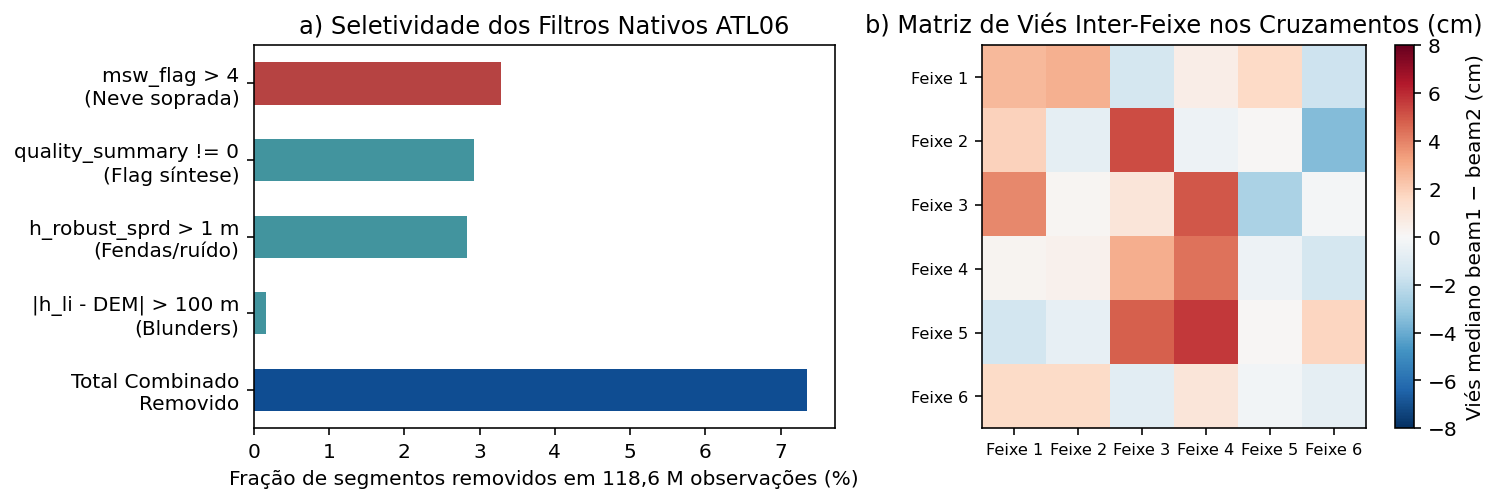

n  bias_m   mad_m  max_dt_years  expected_change_removed
beam1 beam2                                                           
5     6      49  0.0171  0.2051          0.25                    False
6     4      48  0.0097  0.1403          0.25                    False
5     3      47  0.0475  0.0853          0.25                    False
6     3      46 -0.0086  0.1535          0.25                    False
4     1      43  0.0023  0.1150          0.25                    False
      6      42 -0.0138  0.1369          0.25                    False
      5      42 -0.0042  0.0755          0.25                    False
      4      42  0.0433  0.1742          0.25                    False
1     3      40 -0.0142  0.2275          0.25                    False
      2      40  0.0284  0.0864          0.25                    False

In [2]:
# Análise do viés inter-feixe (cruzamentos com Δt < 0,25 ano e mudança esperada removida)
ib_mat = ibeam.pivot(index="beam1", columns="beam2", values="bias_m")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
criterios = ["msw_flag > 4\n(Neve soprada)", "quality_summary != 0\n(Flag síntese)", "h_robust_sprd > 1 m\n(Fendas/ruído)", "|h_li - DEM| > 100 m\n(Blunders)", "Total Combinado\nRemovido"]
pcts = [3.28, 2.93, 2.83, 0.17, 7.35]
ax[0].barh(criterios[::-1], pcts[::-1], color=["#0F4D92", "#42949E", "#42949E", "#42949E", "#B64342"], height=0.55)
ax[0].set_xlabel("Fração de segmentos removidos em 118,6 M observações (%)")
ax[0].set_title("a) Seletividade dos Filtros Nativos ATL06")

im = ax[1].imshow(ib_mat.to_numpy(dtype=float) * 100, cmap="RdBu_r", vmin=-8, vmax=8)
ax[1].set_xticks(range(len(ib_mat.columns)))
ax[1].set_xticklabels([f"Feixe {c}" for c in ib_mat.columns], fontsize=8)
ax[1].set_yticks(range(len(ib_mat.index)))
ax[1].set_yticklabels([f"Feixe {r}" for r in ib_mat.index], fontsize=8)
plt.colorbar(im, ax=ax[1], label="Viés mediano beam1 − beam2 (cm)")
ax[1].set_title("b) Matriz de Viés Inter-Feixe nos Cruzamentos (cm)")
plt.tight_layout()

ibeam.sort_values("n", ascending=False).head(10).set_index(["beam1", "beam2"]).round(4)

---
## 3. Demonstração Executável: Diferenciação Topográfica REMA v2 e Filtro Along-Track por MAD Móvel

O módulo `thwaites.qc.filttrack` opera sobre $h_{\text{res}} = h_{\text{corr}} - h_{\text{REMA}}$. Em vez de usar média e desvio-padrão amostral (que são corrompidos pelo próprio *blunder* que se deseja detectar), aplica-se uma janela deslizante de comprimento $W = 21$ segmentos ao longo de cada trilha contínua `(rgt, cycle, beam)` e rejeita-se qualquer ponto que viole:
$$|h_{\text{res},i} - \operatorname{mediana}_{j \in W(i)}(h_{\text{res},j})| > \max\left(5{,}0 \times 1{,}4826 \times \operatorname{MAD}_{W(i)},\; 0{,}10\text{ m}\right)$$

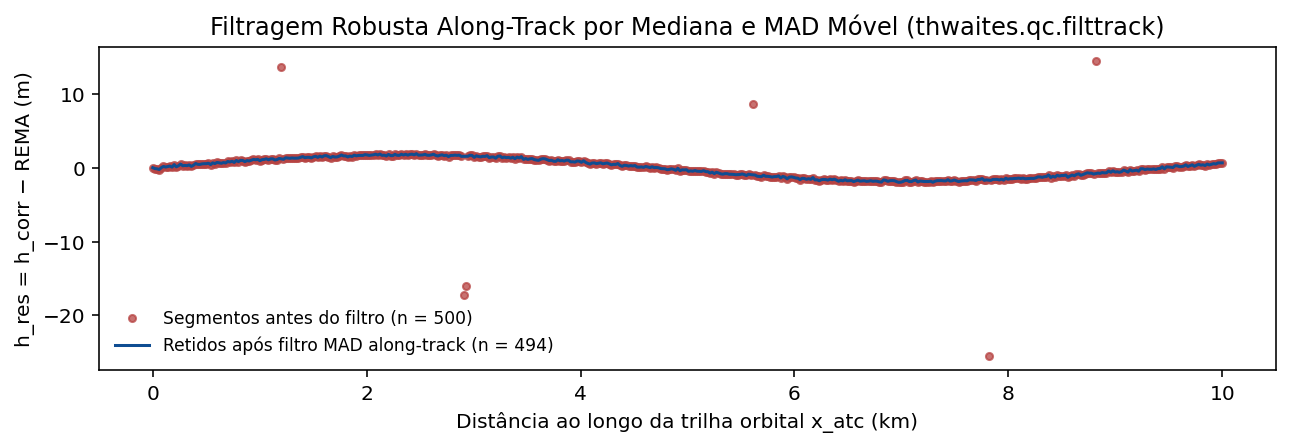

In [3]:
from thwaites.qc.filttrack import filter_along_track

rng = np.random.default_rng(14)
n_pts = 500
x_atc = np.linspace(0, 10_000, n_pts)
h_res_true = 1.8 * np.sin(x_atc / 1500.0)
h_res_obs = h_res_true + rng.normal(0, 0.09, size=n_pts)
blunders = [60, 145, 146, 280, 390, 440]
h_res_obs[blunders] += np.array([12.5, -19.0, -17.5, 9.8, -24.0, 15.2])

df_sim = pd.DataFrame({
    "x": -1550e3 + x_atc, "y": -420e3 + 0.2 * x_atc,
    "h_res": h_res_obs, "h_corr": h_res_obs, "h_elv": h_res_obs,
    "t_year": np.full(n_pts, 2023.5), "beam": np.ones(n_pts, dtype=int),
    "rgt": np.full(n_pts, 5, dtype=int), "cycle": np.full(n_pts, 19, dtype=int),
})
df_filtered = filter_along_track(df_sim, cfg)

fig, ax = plt.subplots(figsize=(9.0, 3.2))
ax.plot(x_atc / 1e3, h_res_obs, "o", color="#B64342", ms=3.5, alpha=0.75, label=f"Segmentos antes do filtro (n = {len(df_sim)})")
ax.plot((df_filtered["x"].to_numpy() + 1550e3) / 1e3, df_filtered["h_res"].to_numpy(), "-", color="#0F4D92", lw=1.5, label=f"Retidos após filtro MAD along-track (n = {len(df_filtered)})")
ax.set_xlabel("Distância ao longo da trilha orbital x_atc (km)")
ax.set_ylabel("h_res = h_corr − REMA (m)")
ax.set_title("Filtragem Robusta Along-Track por Mediana e MAD Móvel (thwaites.qc.filttrack)")
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout()